# Arbitrage with estimated utility curves

Figure 5-8 of the paper using MATH, CodeContests, AIME 2024/2025, Global-MMLU-Lite and MMLU-Pro: the empirical-Bayes pass@k estimator against the plug-in, with the unbiased estimator of Chen et al. on all recorded attempts as the oracle.

In [1]:
import os, json, time, warnings

warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from utils import *

## Figure 5: arbitrage on estimated curves

For each benchmark and calibration size $n \in \{2, 4, 8, 16\}$, ten random draws of $n$ attempts per cell. In each replicate (`calibrate_one`) the arbitrageur allocates on the estimated curves and is scored on the oracle curves of the held-out attempts, at the budget the oracle needs for each target solve rate.

In [2]:
ESTIMATORS = (
    "geom",
    "zibb",
)  # "geom": the plug-in 1 - (1 - c/n)^k; "zibb": ours, the zero-inflated Beta-Binomial posterior predictive


def calibrate_one(args):
    """One replicate: the arbitrageur allocates on curves estimated from `num_calibration_attempts` per cell and is
    scored on the oracle curves of the held-out attempts."""
    benchmark_name, num_calibration_attempts, replicate = args
    benchmark, models, attempt_price, num_successes, num_attempts, budget = load_benchmark(benchmark_name)
    rng = np.random.default_rng(SEED + 1000 * num_calibration_attempts + replicate)
    calib_successes, calib_attempts, heldout_successes, heldout_attempts = split_attempts(
        num_successes, num_attempts, num_calibration_attempts, rng
    )
    # every curve is frozen at the attempts held out for its cell, and no money is spent past them
    max_attempts, attempt_cap = heldout_attempts.max(0), heldout_attempts
    oracle_solve_prob = curves_from_counts(
        heldout_successes,
        heldout_attempts,
        attempt_price,
        budget,
        "chen",
        max_attempts,
        attempt_cap,
    )  # held-out attempts, Chen's unbiased estimator
    spend_cap = attempt_cap * attempt_price  # [problem, model] dollars
    oracle_expected_spend = [
        expected_spend_curve(oracle_solve_prob[:, model, :], budget, spend_cap[:, model])
        for model in range(len(models))
    ]
    budget_cap = budget_caps(max_attempts, attempt_price)
    result = dict(key=benchmark_name, n_sub=num_calibration_attempts, rep=replicate)  # keys read by summarize_calibration
    for estimator in ESTIMATORS:
        estimated_solve_prob = curves_from_counts(
            calib_successes,
            calib_attempts,
            attempt_price,
            budget,
            estimator,
            max_attempts,
            attempt_cap,
        )
        claimed_solve, claimed_spend, allocs = arbitrage_frontier(
            estimated_solve_prob, budget, budget_cap=budget_cap
        )  
        realized_solve, realized_spend = score_allocations(
            oracle_solve_prob, oracle_expected_spend, budget, allocs
        )  
        result[estimator] = dict(
            claimed=(claimed_solve, claimed_spend),
            realized=(realized_solve, realized_spend),
        )
    return result


def calibrate(benchmark_names):
    """{benchmark: [calibrate_one results]} over the calibration sizes and R replicates."""
    replicates_by_benchmark = {}
    for benchmark_name in benchmark_names:
        start_time = time.time()
        jobs = [
            (benchmark_name, num_calibration_attempts, replicate)
            for num_calibration_attempts in CALIBRATION_SIZES
            for replicate in range(NUM_REPLICATES)
        ]
        replicates = [calibrate_one(job) for job in jobs]
        replicates_by_benchmark[benchmark_name] = replicates
        print(f"[{benchmark_name}] {len(replicates)} replicates in {time.time() - start_time:.0f}s")
    return replicates_by_benchmark

[monkey_math] 40 replicates in 26s
[monkey_codecontests] 40 replicates in 8s
[irsl_aime2024] 40 replicates in 16s
[irsl_aime2025] 40 replicates in 15s
[irsl_gmmlu] 40 replicates in 20s
[irsl_mmlupro] 40 replicates in 17s
[monkey_math] 40 replicates
  n=2 attempts per cell: solve rate reached at the budget the oracle needs for each target (medians over replicates)
     budget | oracle |       Plug-in | Beta-binomial
   6.89e+05 |    50% |         48.0% |         48.1%
   2.12e+06 |    70% |         65.0% |         67.8%
   4.09e+06 |    80% |         75.2% |         78.4%
   1.04e+07 |    90% |         85.9% |         88.3%
    2.5e+07 |    95% |         86.7% |         94.0%
  n=4 attempts per cell: solve rate reached at the budget the oracle needs for each target (medians over replicates)
     budget | oracle |       Plug-in | Beta-binomial
   6.89e+05 |    50% |         48.7% |         48.7%
   2.12e+06 |    70% |         67.0% |         68.6%
   4.09e+06 |    80% |         76.0% |  

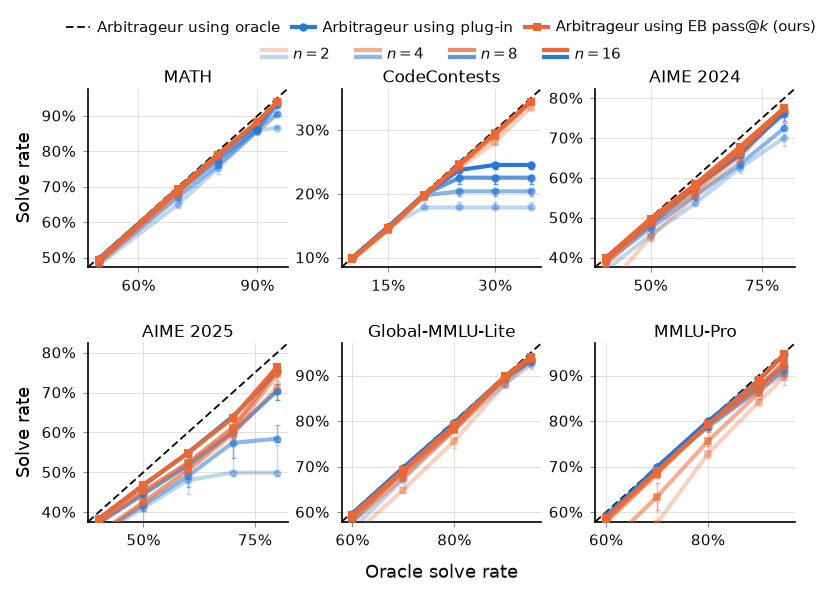

In [3]:
BENCHMARKS = [
    "monkey_math",
    "monkey_codecontests",
    "irsl_aime2024",
    "irsl_aime2025",
    "irsl_gmmlu",
    "irsl_mmlupro",
]
replicates = calibrate(BENCHMARKS)
summarize_calibration(replicates)  # summarizes the replicates at each benchmark's target solve rates
draw_calibration()

## Estimation error

Paired difference in pass@k RMSE between the plug-in and our estimator over 100 calibration draws of $n = 8$ attempts per cell (`gaps`).

In [4]:
def gaps(benchmark_name, num_calibration_attempts, num_draws):
    """{estimator: (draws,) paired RMSE gap, plug-in minus that estimator, averaged over models and k}."""
    oracle_passk, estimates = estimate_passk_draws(
        benchmark_name, num_calibration_attempts, num_draws
    )  # [problem, model, k] and {estimator: [draw, problem, model, k]}

    def rmse_per_draw(
        passk,
    ):  # [draw, problem, model, k] -> [draw]: RMSE over problems, then mean over models and k
        squared_error = (passk - oracle_passk[None]) ** 2
        return np.sqrt(squared_error.mean(1)).mean((1, 2))

    plugin_rmse = rmse_per_draw(estimates["plug"])
    return {estimator: plugin_rmse - rmse_per_draw(estimates[estimator]) for estimator in GAP_SERIES}


def gap_dist(benchmarks, ncols=None):
    """One panel per benchmark, `ncols` per row (default: all in one row); the shared x label sits under the bottom
    row and each row's first panel carries the y label. `benchmarks`: (name in the registry, display name) pairs.
    """
    num_panels = len(benchmarks)
    ncols = ncols or num_panels
    nrows = -(-num_panels // ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(5.5, 1.55 * nrows), squeeze=False)
    for ax, (benchmark_name, display_name) in zip(axs.ravel(), benchmarks):
        gap_by_estimator = gaps(benchmark_name, GAP_CALIBRATION_SIZE, GAP_DRAWS)
        draw_gap_panel(ax, gap_by_estimator, display_name)
        print(
            f"[{benchmark_name}] "
            + "  ".join(
                f"{estimator}: plug-in worse in {np.mean(gap > 0) * 100:3.0f}% of draws, median gap {np.median(gap):+.4f}"
                for estimator, gap in gap_by_estimator.items()
            ),
            flush=True,
        )
    for ax in axs.ravel()[num_panels:]:
        ax.set_visible(False)
    for row in axs:
        row[0].set_ylabel("Density", fontsize=FS["label"])
    fig.tight_layout(w_pad=0.4, h_pad=1.6)
    pos_first, pos_last = axs[-1][0].get_position(), axs[-1][-1].get_position()
    fig.text(
        (pos_first.x0 + pos_last.x1) / 2,
        pos_first.y0 - 0.175 / nrows,
        r"Plug-in RMSE $-$ EB pass@$k$ (ours) RMSE",
        ha="center",
        va="top",
        fontsize=FS["label"],
        color=INK,
    )

[monkey_math] draw 20 of 100
[monkey_math] draw 40 of 100
[monkey_math] draw 60 of 100
[monkey_math] draw 80 of 100
[monkey_math] draw 100 of 100
[monkey_math] ours: plug-in worse in 100% of draws, median gap +0.1002
[monkey_codecontests] draw 20 of 100
[monkey_codecontests] draw 40 of 100
[monkey_codecontests] draw 60 of 100
[monkey_codecontests] draw 80 of 100
[monkey_codecontests] draw 100 of 100
[monkey_codecontests] ours: plug-in worse in 100% of draws, median gap +0.0051
[irsl_aime2024] draw 20 of 100
[irsl_aime2024] draw 40 of 100
[irsl_aime2024] draw 60 of 100
[irsl_aime2024] draw 80 of 100
[irsl_aime2024] draw 100 of 100
[irsl_aime2024] ours: plug-in worse in 100% of draws, median gap +0.0549
[irsl_aime2025] draw 20 of 100
[irsl_aime2025] draw 40 of 100
[irsl_aime2025] draw 60 of 100
[irsl_aime2025] draw 80 of 100
[irsl_aime2025] draw 100 of 100
[irsl_aime2025] ours: plug-in worse in 100% of draws, median gap +0.0342
[irsl_gmmlu] draw 20 of 100
[irsl_gmmlu] draw 40 of 100
[irs

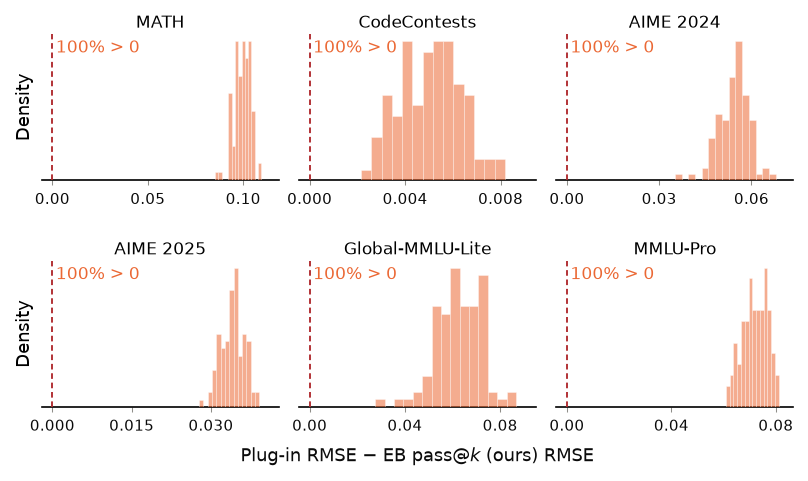

In [5]:
gap_dist(GAP_BENCHMARKS + GAP_BENCHMARKS_APPENDIX, ncols=3)